# Low Rank Adaptation (LoRA) Lab Notebook

## Learning Objectives

- Understand the mathematics behind LoRA
- Implement and compare full fine-tuning vs LoRA with different ranks
- Analyze convergence behavior and final performance
- Visualize the subspace where LoRA constrains updates
- Analyze gradient norms in original vs LoRA parameter space
- Explore the effect of scaling factors and initialization strategies

## Prerequisites

- Basic understanding of neural network forward/backward pass
- Familiarity with matrix operations and rank
- Python knowledge (numpy, matplotlib only)


### Setup: Imports

First, import numpy for numerical operations and matplotlib for visualization. We disable warnings for a cleaner notebook display.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print(f"NumPy version: {np.__version__}")
print("All imports successful.")


NumPy version: 2.2.6
All imports successful.


## Part 1: Dataset Exploration

We use synthetic datasets to understand how different data distributions affect LoRA performance.

### Concentric Circles Dataset

This is a classic nonlinear classification problem where one class is completely surrounded by the other.


In [2]:
np.random.seed(42)
n_samples = 500

# Class 0: inner circle
r1, theta1 = 0.5 * np.sqrt(np.random.rand(n_samples // 2)), 2*np.pi*np.random.rand(n_samples//2)

# Class 1: outer ring
r2, theta2 = 1.0 * np.sqrt(np.random.rand(n_samples // 2)), 2*np.pi*np.random.rand(n_samples//2)

X_circles = np.zeros((2, n_samples))
y_circles = np.zeros(n_samples)
X_circles[0,:n_samples//2] = r1*np.cos(theta1)
X_circles[1,:n_samples//2] = r1*np.sin(theta1)
y_circles[:n_samples//2] = 0
X_circles[0,n_samples//2:] = r2*np.cos(theta2)
X_circles[1,n_samples//2:] = r2*np.sin(theta2)
y_circles[n_samples//2:] = 1

# Scale data for better training
scale_factor = max(np.abs(X_circles).max(), 1e-8)
X_circles *= 2.0 / scale_factor

print(f"X shape: {X_circles.shape}, y shape: {y_circles.shape}")
print(f"Class 0 samples: {np.sum(y_circles == 0)}, Class 1 samples: {np.sum(y_circles == 1)}")


X shape: (2, 500), y shape: (500,)
Class 0 samples: 250, Class 1 samples: 250


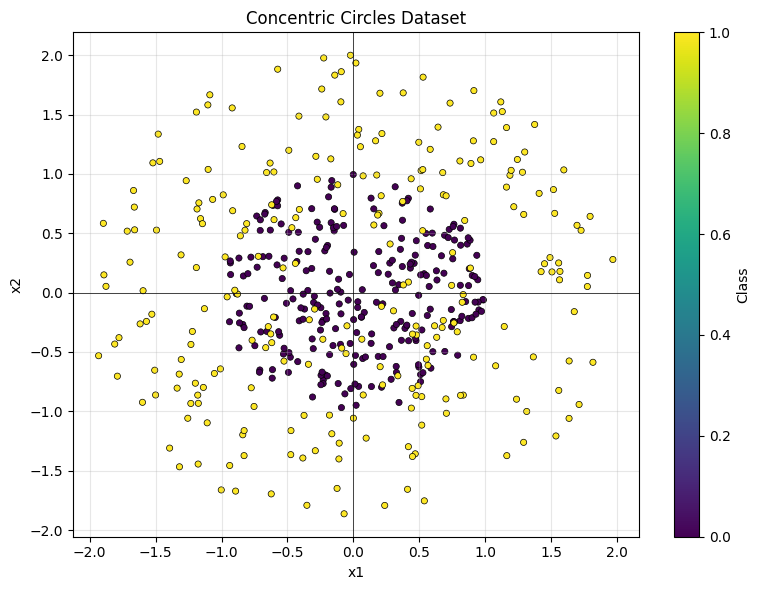

In [3]:
plt.figure(figsize=(8,6))
plt.scatter(X_circles[0], X_circles[1], c=y_circles, cmap='viridis', s=20, edgecolors='k', linewidths=0.5)
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Concentric Circles Dataset')
plt.colorbar(label='Class')
plt.axhline(y=0,color='k',lw=0.5); plt.axvline(x=0,color='k',lw=0.5)
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


**Exercise 1:** Describe the decision boundary you observe.

a) Is this a linear or nonlinear classification problem?
b) What characteristics make it challenging for a neural network?

> **Hint:** Think about what mathematical operation is needed to separate the two classes.


### Moons Dataset

A more complex manifold where two interleaved half-moons need to be classified. This tests the network's ability to learn curved decision boundaries.


In [4]:
np.random.seed(123)
n_moons = 500; n1 = n_moons // 2

X_moons = np.zeros((2, n_moons))
y_moons = np.zeros(n_moons)

# Class 0: upper moon
theta0 = np.linspace(0, np.pi, n1) + np.random.randn(n1)*0.15
X_moons[0,:n1] = np.cos(theta0)+0.3*np.random.randn(n1)
X_moons[1,:n1] = np.sin(theta0)-0.1+0.1*np.random.randn(n1)
y_moons[:n1] = 0

# Class 1: lower moon
theta1 = np.linspace(0, np.pi, n1) + np.random.randn(n1)*0.15
X_moons[0,n1:] = -np.cos(theta1)+0.7+0.3*np.random.randn(n1)
X_moons[1,n1:] = -np.sin(theta1)+0.1+0.1*np.random.randn(n1)
y_moons[n1:] = 1

scale_moons = max(np.abs(X_moons).max(), 1e-8)
X_moons *= 1.5 / scale_moons

print(f"Moons - X shape: {X_moons.shape}, y shape: {y_moons.shape}")


Moons - X shape: (2, 500), y shape: (500,)


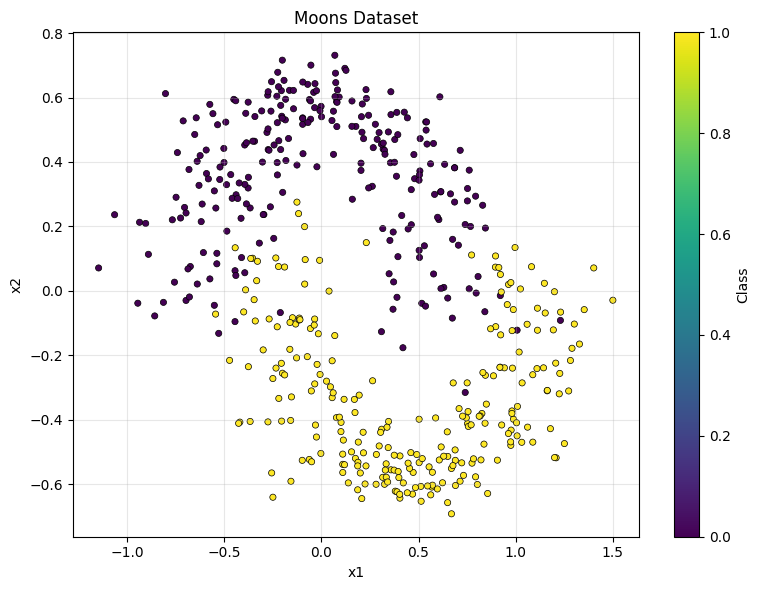

In [5]:
plt.figure(figsize=(8,6))
plt.scatter(X_moons[0], X_moons[1], c=y_moons, cmap='viridis', s=20, edgecolors='k', linewidths=0.5)
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Moons Dataset'); plt.colorbar(label='Class')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Exercise 2:** Compare the moons dataset to concentric circles.
a) What decision boundary shape is needed for each?
b) When might LoRA be particularly useful with similar data patterns?

> **Hint:** Think about how complex the boundary is and what that means for model capacity.


## Part 2: Base Neural Network Classes

These classes form the foundation of our implementation.

### Activation Functions


In [6]:
class Activation():
    def __init__(self, f, f_prime): self.f, self.d = f, f_prime
    def __call__(self, n): return self.f(n)

class Linear(Activation):
    def __init__(self): super().__init__(lambda x: x, lambda x: np.ones_like(x))

class PosLinear(Activation):
    def __init__(self):
        super().__init__(lambda x: np.where(np.asarray(x)>0, x, 0), lambda x: np.where(np.asarray(x)>0, 1, 0))

class Sigmoid(Activation):
    def _sig(self, n): return 1/(1+np.exp(-n))
    def __init__(self): super().__init__(self._sig, lambda x: self._sig(x)*(1-self._sig(x)))

class GELU(Activation):
    @staticmethod
    def _gelu(n):
        u = np.sqrt(2/np.pi)*(n + 0.044715*n**3)
        return 0.5*n*(1+np.tanh(u))
    @staticmethod
    def _gelu_prime(n):
        a = np.sqrt(2/np.pi); u = a*(n+0.044715*n**3); t = np.tanh(u)
        return 0.5*(1+t)+0.5*n*(1-t**2)*a*(1+3*0.044715*n**2)
    def __init__(self): super().__init__(GELU._gelu, GELU._gelu_prime)


### Neuron Class

A single neuron performs: $a = f(Wx + b)$ where $W$ is the weight matrix and $b$ is the bias vector.


In [ ]:
class Neuron():
    def __init__(self, weights, bias, activation):
        w = np.array(weights)
        self.W = w if w.ndim==2 else np.expand_dims(w,0)
        self.S, self.R = self.W.shape
        self.b = np.array(bias) if bias is not None else None
        if self.b is not None:
            while self.b.ndim < 2: self.b = np.expand_dims(self.b, axis=1)
        self.activation = activation
        self.a = self.n = self.s = 0

    def __call__(self, input): #cline forgot to add this
        return self.forward(input)

    def forward(self, input):
        p = np.array(input)
        p = p.reshape(-1,1) if p.ndim==1 else p
        self.n = self.W @ p
        if self.b is not None: self.n += self.b
        self.a = self.activation(self.n)
        self.p_forward = p.copy()
        return self.a


### Layer and Neural Network

Layers chain neurons, and `NeuralNet` stacks layers with proper forward/backward propagation.


In [27]:
class Layer():
    def __init__(self, n_features=0, n_outputs=0, activation=Sigmoid(), bias=True):
        w = np.random.randn(n_outputs, n_features)
        b = np.random.randn(n_outputs,1) if bias else None
        self.neuron = Neuron(w, b, activation)
    def forward(self, input): return self.neuron(input)

class NeuralNet():
    def __init__(self, layers=None, n_features=0, hidden_dim=0, n_hidden=0, activation=Sigmoid()):
        self.layers = []
        if layers is not None: self.layers = list(layers)
        else:
            prev = n_features
            for i in range(n_hidden):
                out = hidden_dim if i < n_hidden-1 else n_features
                act = activation if i < n_hidden-1 else Linear()
                self.layers.append(Layer(n_features=prev, n_outputs=out, activation=act))
                prev = out
    def __call__(self,input): #cline forgot this
        return self.forward(input)

    def forward(self, x):
        a = x
        for layer in self.layers: a = layer.forward(a)
        self.a0 = x; return a

    def backward(self, error):
        for i in range(len(self.layers)-1,-1,-1):
            n = self.layers[i].neuron
            n.s = error * n.activation.d(n.n)
            if i > 0: error = n.W.T @ n.s


In [29]:
np.random.seed(42)
nnet_test = NeuralNet(n_features=2, hidden_dim=16, n_hidden=3)
print('Network layers:')
for i,l in enumerate(nnet_test.layers):
    print(f'  Layer {i}: W={l.neuron.W.shape}, b={l.neuron.b.shape if l.neuron.b is not None else None}')

# Quick test on first data point
x_test = X_circles[:,0].reshape(2,1)
out = nnet_test(x_test)
print(f'Forward output shape: {out.shape}')


Network layers:
  Layer 0: W=(16, 2), b=(16, 1)
  Layer 1: W=(16, 16), b=(16, 1)
  Layer 2: W=(2, 16), b=(2, 1)
Forward output shape: (2, 1)


**Exercise 3:** Experiment with GELU activation.
a) Create a network using `GELU` activation instead of `Sigmoid`.
b) Test its forward pass on the concentric circles dataset.

> **Hint:** Pass `activation=GELU()` when creating your `NeuralNet`.


## Part 3: Optimizer Classes

### Base Optimizers


In [10]:
class Optimizer():
    def __init__(self, network, learning_rate): self.network, self.lr = network, learning_rate
    def update(self): pass

class SteepestDescent(Optimizer):
    def update(self):
        for layer in self.network.layers:
            n = layer.neuron
            dW = -self.lr * n.s @ n.p_forward.T if hasattr(n,'p_forward') else None
            if dW is not None: n.W += dW
            if n.b is not None: n.b += -self.lr*np.sum(n.s,keepdims=True)

class MOBP(Optimizer):
    def __init__(self, network, learning_rate, gamma=0.9):
        super().__init__(network, learning_rate); self.gamma = gamma
    def update(self):
        a0 = self.network.a0; next_a = None
        for layer in self.network.layers:
            next_a = layer.neuron(a0)
            dW = self.lr * layer.neuron.s @ a0.T
            layer.neuron.delta_W = self.gamma*layer.neuron.delta_W - (1-self.gamma)*dW
            layer.neuron.W += layer.neuron.delta_W
            if layer.neuron.b is not None:
                db = self.lr*np.sum(layer.neuron.s,keepdims=True)
                layer.neuron.delta_b = self.gamma*layer.neuron.delta_b-(1-self.gamma)*db
                layer.neuron.b += layer.neuron.delta_b
            a0 = next_a


**Exercise 4:** Implement AdaGrad optimizer.

AdaGrad adapts the learning rate per-parameter using accumulated squared gradients:

$$\text{cache} \leftarrow \text{cache} + g^2$$
$$\theta \leftarrow \theta - \frac{\eta}{\sqrt{\text{cache}}+\epsilon} \cdot g$$


In [11]:
class AdaGrad(Optimizer):
    def __init__(self, network, learning_rate, epsilon=1e-8):
        super().__init__(network, learning_rate); self.epsilon = epsilon
        self.cache_W = [None]*len(network.layers)
        self.cache_b = [None]*len(network.layers)
        for i,layer in enumerate(network.layers):
            n = layer.neuron; self.cache_W[i] = np.zeros_like(n.W)
            if n.b is not None: self.cache_b[i] = np.zeros_like(n.b)

    def update(self):
        for i,layer in enumerate(self.network.layers):
            n = layer.neuron
            gW = -self.lr * n.s @ n.p_forward.T if hasattr(n,'p_forward') else None
            self.cache_W[i] += gW**2; n.W -= (self.lr/np.sqrt(self.cache_W[i]+self.epsilon))*gW
            if n.b is not None:
                gb = -self.lr*np.sum(n.s,keepdims=True)
                self.cache_b[i] += gb**2; n.b -= (self.lr/np.sqrt(self.cache_b[i]+self.epsilon))*gb


### VLBP Trainer

VLBP (Variable Learning Rate BackProp) automatically adjusts learning rates during training for faster convergence.


In [12]:
class VLBP():
    def __init__(self, network, optimizer, n_epochs, sensitivity=0.05, decrease_factor=0.1, increase_factor=1.1):
        self.network,self.optimizer,self.n_epochs = network,optimizer,n_epochs
        self.sensitivity,self.decrease_factor,self.increase_factor = sensitivity,decrease_factor,increase_factor
        self.batch_size = None

    def _clone_weights(self):
        state={}
        for i,l in enumerate(self.network.layers):
            state[(i,'W')]=l.neuron.W.copy()
            if l.neuron.b is not None: state[(i,'b')]=l.neuron.b.copy()
        return state

    def _restore_weights(self, state):
        for i,l in enumerate(self.network.layers):
            l.neuron.W = state[(i,'W')].copy()
            if l.neuron.b is not None: l.neuron.b = state[(i,'b')].copy()

    def train(self, data, labels):
        losses, prev_loss = [], None
        n_samples = data.shape[1]
        for epoch in range(self.n_epochs):
            weight_state = self._clone_weights()
            epoch_loss = 0.0
            for start in range(0,n_samples,self.batch_size or n_samples):
                stop = min(start+self.batch_size or n_samples, n_samples)
                x,y = data[:,start:stop], labels[:,start:stop]
                pred = self.network(x); errors = y-pred
                loss = np.sum(errors**2)
                self.network.backward(errors); self.optimizer.update()
                epoch_loss += float(loss)
            losses.append(epoch_loss)
            rel_change = (losses[-1]-prev_loss)/abs(prev_loss) if prev_loss and abs(prev_loss)>1e-8 else float('inf')
            if prev_loss is None or rel_change < 0:
                self.optimizer.lr *= self.increase_factor if rel_change<0 else 1.0
            elif rel_change > self.sensitivity:
                self._restore_weights(weight_state)
                self.optimizer.lr *= self.decrease_factor
            prev_loss = losses[-1]
        return losses


## Part 4: Low Rank Adaptation (LoRA)

### Mathematics of LoRA

Instead of updating the full weight matrix $W$, LoRA constrains updates to a low-rank subspace:

$$W_{\text{new}} = W + BA$$
- $W$ pretrained (**frozen**), $B \in \mathbb{R}^{S \times r}$, $A \in \mathbb{R}^{r \times R}$ trainable
- Rank $r \ll \min(S,R)$ (typically 1-16)

**Forward:** $a = f((W + BA)x + b)$
**Gradients (frozen W):** dL/dA = s * (Bx)^T, dL/dB = A^T * s * x^T


In [24]:
class LoRaNeuron(Neuron):
    def __init__(self, pretrained_neuron=None, lora_rank=0, lora_enabled=False): 
        if pretrained_neuron is not None:
            self.W = np.asarray(pretrained_neuron.W).copy()
            self.S, self.R = pretrained_neuron.S, pretrained_neuron.R
            self.b = pretrained_neuron.b.copy() if pretrained_neuron.b is not None else None
            self.activation = pretrained_neuron.activation
        else: super().__init__(None, None, None)
        self.lora_rank, self.lora_enabled = lora_rank, lora_enabled
        self.A, self.B = None, None
        self.accumulated_dA, self.accumulated_dB = None, None
        self.p_forward = None

    def enable_lora(self, rank=None):
        if rank is not None: self.lora_rank = rank
        if self.W is None or self.lora_rank <= 0: raise ValueError('W and rank > 0')
        self.A = np.random.randn(self.S, self.lora_rank) * 0.01
        self.B = np.zeros((self.lora_rank, self.R))
        self.lora_enabled = True
        self.reset_lora_gradients()

    def reset_lora_gradients(self):
        if self.A is not None and self.B is not None: 
            self.accumulated_dA = np.zeros_like(self.A)
            self.accumulated_dB = np.zeros_like(self.B)

    def forward(self, input):
        if not self.lora_enabled: return super().forward(input)
        p = np.array(input)
        p = p.reshape(-1,1) if p.ndim==1 else p
        scaled_W = self.W + self.B @ self.A
        self.n = scaled_W @ p
        if self.b is not None: self.n += self.b
        self.a = self.activation(self.n)
        self.p_forward = p.copy()
        return self.a


In [30]:
class LoRaNet(NeuralNet):
    def __init__(self, layers=None, n_features=0, hidden_dim=0, n_hidden=0, activation=Sigmoid(), pretrained_net=None, freeze_weights=False): 
        if pretrained_net is not None:
            super().__init__(pretrained_net.layers) #changed this from recursive
            '''
            for i,l in enumerate(super().layers):
                l.neuron.W = pretrained_net.layers[i].neuron.W.copy()
                if pretrained_net.layers[i].neuron.b is not None: 
                    l.neuron.b = pretrained_net.layers[i].neuron.b.copy()
                l.neuron = LoRaNeuron(l.neuron, lora_enabled=False)
                
            '''
        else: super().__init__(layers, n_features, hidden_dim, n_hidden, activation)
        self.freeze_weights = freeze_weights
        
    def init_lora(self, layer_idx, rank, scale=1.0):
        neuron = self.layers[layer_idx].neuron
        if not isinstance(neuron, LoRaNeuron): 
            neuron = LoRaNeuron(pretrained_neuron=neuron)
            self.layers[layer_idx].neuron = neuron
        neuron.enable_lora(rank)
        neuron.A *= scale / rank

    def reset_lora_grads(self):
        for l in self.layers: l.neuron.reset_lora_gradients()

    def backward(self, error): 
        if not self.freeze_weights: return super().backward(error)
        super().backward(error)
        for layer in self.layers:
            n = layer.neuron
            if not n.lora_enabled or n.A is None: continue
            h = n.B @ n.p_forward
            n.accumulated_dA += n.s @ h.T
            n.accumulated_dB += n.A.T @ n.s @ n.p_forward.T


In [22]:
class LoRaSteepestDescent(Optimizer):
    def __init__(self, network, lr): super().__init__(network, lr)
    def updateLoRa(self):
        a0 = self.network.a0; next_a = None
        for layer in self.network.layers:
            n = layer.neuron; next_a = n(a0)
            if n.lora_enabled and n.accumulated_dA is not None:
                n.A -= self.lr * n.accumulated_dA
                n.B -= self.lr * n.accumulated_dB
                n.reset_lora_gradients()
            a0 = next_a
    def update(self): pass

class LoRaMOBP(MOBP):
    def __init__(self, network, lr, gamma=0.9): 
        super().__init__(network, lr, gamma)
    def _init_neurons(self):
        for l in self.network.layers:
            n = l.neuron
            if hasattr(n,'A') and n.A is not None: 
                n.delta_A = np.zeros_like(n.A); n.delta_B = np.zeros_like(n.B)
    def updateLoRa(self):
        a0 = self.network.a0; next_a = None
        for layer in self.network.layers:
            n = layer.neuron; next_a = n(a0)
            if n.lora_enabled and n.accumulated_dA is not None:
                dA, dB = n.accumulated_dA, n.accumulated_dB
                if not hasattr(n,'delta_A'): 
                    n.delta_A = np.zeros_like(dA); n.delta_B = np.zeros_like(dB)
                n.delta_A = self.gamma*n.delta_A-(1-self.gamma)*dA
                n.A += n.delta_A
                n.delta_B = self.gamma*n.delta_B-(1-self.gamma)*dB
                n.B += n.delta_B
                n.reset_lora_gradients()
            a0 = next_a
    def update(self): pass


## Part 5: Rank Comparison Experiments

Train networks with different LoRA ranks and compare convergence/final loss.


In [31]:
np.random.seed(42)
ranks = [1, 2, 5, 10]
n_epochs_lo = 300; lr = 0.01; n_trials = 3
loa_losses = {r: [] for r in ranks}

for trial in range(n_trials):
    base_net = NeuralNet(n_features=2, hidden_dim=32, n_hidden=4)
    for r in ranks:
        lora_net = LoRaNet(pretrained_net=base_net, freeze_weights=True)
        for li in range(len(lora_net.layers)): lora_net.init_lora(li, r)
        opt = LoRaSteepestDescent(lora_net, lr)
        t_losses = []; n_s = X_circles.shape[1]
        for ep in range(n_epochs_lo):
            s0 = 0
            while s0 < n_s:
                stop = min(s0+64, n_s)
                pred = lora_net(X_circles[:,s0:stop])
                err = (y_circles[s0:stop].reshape(1,-1)-pred)
                lora_net.backward(err); opt.update(); s0 += 64
            t_losses.append(float(np.sum((y_circles.reshape(1,-1)-lora_net(X_circles))**2)/n_s))
        loa_losses[r].append(t_losses)

plt.figure(figsize=(10,6))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(ranks)))
for i, r in enumerate(ranks):
    ml = np.mean(loa_losses[r], axis=1); sl = np.std(loa_losses[r], axis=1)
    plt.plot(range(n_epochs_lo), ml, label=f'Rank {r}', color=colors[i], linewidth=2)
    plt.fill_between(range(n_epochs_lo), ml-sl, ml+sl, alpha=0.15, color=colors[i])
plt.xlabel('Epoch'); plt.ylabel('Mean Loss (MSE)')
plt.title('LoRA Rank Comparison - Concentric Circles'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()

print("\nFinal losses (mean ± std):")
for r in ranks:
    ml = np.mean(loa_losses[r][-1]); sl = np.std(loa_losses[r][-1])
    print(f"  Rank {r:>2d}: {ml:.6f} ± {sl:.6f}")


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 32 is different from 2)

**Exercise 5:** Analyze the rank comparison results.

a) Which ranks converge fastest? Which achieve the lowest final loss?
b) Why might low ranks (1, 2) have limitations for this problem?
c) When would you expect very high ranks to be necessary?

> **Hint:** Think about the rank of the optimal weight matrix needed to solve this task.


In [ ]:
np.random.seed(42)
moon_losses = {r: [] for r in ranks}
for trial in range(n_trials):
    base_moons = NeuralNet(n_features=2, hidden_dim=32, n_hidden=4)
    for r in ranks:
        loa_m = LoRaNet(pretrained_net=base_moons, freeze_weights=True)
        for li in range(len(loa_m.layers)): loa_m.init_lora(li, r)
        opt_m = LoRaSteepestDescent(loa_m, lr)
        ml = []; n_s = X_moons.shape[1]
        for ep in range(n_epochs_lo):
            s0 = 0
            while s0 < n_s:
                stop = min(s0+64, n_s)
                pred = loa_m(X_moons[:,s0:stop])
                err = (y_moons[s0:stop].reshape(1,-1)-pred)
                loa_m.backward(err); opt_m.update(); s0 += 64
            ml.append(float(np.sum((y_moons.reshape(1,-1)-loa_m(X_moons))**2)/n_s))
        moon_losses[r].append(ml)

plt.figure(figsize=(10,6))
colors = plt.cm.plasma(np.linspace(0.2, 0.8, len(ranks)))
for i, r in enumerate(ranks):
    ml = np.mean(moon_losses[r], axis=1); sl = np.std(moon_losses[r], axis=1)
    plt.plot(range(n_epochs_lo), ml, label=f'Rank {r}', color=colors[i], linewidth=2)
    plt.fill_between(range(n_epochs_lo), ml-sl, ml+sl, alpha=0.15, color=colors[i])
plt.xlabel('Epoch'); plt.ylabel('Mean Loss (MSE)')
plt.title('LoRA Rank Comparison - Moons Dataset'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()


## Part 6: Gradient Norm Analysis

Compare gradient norms in full vs LoRA spaces to understand information capture.


In [ ]:
np.random.seed(42)
lora_net = LoRaNet(pretrained_net=NeuralNet(n_features=2, hidden_dim=16, n_hidden=3), freeze_weights=True)
for li in range(len(lora_net.layers)): lora_net.init_lora(li, 2)
full_net = NeuralNet(n_features=2, hidden_dim=16, n_hidden=3)

loa_grad_norms = []; full_grad_norms = []
n_s = X_circles.shape[1]
ep_lo = 50; lr_g = 0.01

for ep in range(ep_lo):
    s0 = 0
    while s0 < n_s:
        stop = min(s0+32, n_s)
        xb, yb = X_circles[:,s0:stop], y_circles[s0:stop]

        pred_f = full_net(xb); err_f = (yb.reshape(1,-1)-pred_f)
        for layer in full_net.layers:
            g_norm = np.linalg.norm(layer.neuron.s @ layer.neuron.p_forward.T) if hasattr(layer.neuron,'p_forward') else 0
            full_grad_norms.append(g_norm)
        full_net.backward(err_f)

        pred_l = lora_net(xb); err_l = (yb.reshape(1,-1)-pred_l)
        for layer in lora_net.layers:
            n = layer.neuron
            if n.lora_enabled and hasattr(n, 'accumulated_dA'):
                g_norm = np.linalg.norm(n.accumulated_dA) + np.linalg.norm(n.accumulated_dB)
                loa_grad_norms.append(g_norm)
        lora_net.backward(err_l); s0 += 32

print(f"Full FT grad norm mean: {np.mean(full_grad_norms):.4f}")
print(f"LoRA (rank 2) grad norm mean: {np.mean(loa_grad_norms):.4f}")


In [ ]:
plt.figure(figsize=(10,5))
plt.hist(full_grad_norms, bins=50, alpha=0.7, label='Full FT', density=True)
plt.hist(loa_grad_norms, bins=50, alpha=0.7, label='LoRA (rank 2)', density=True)
plt.xlabel('Gradient Norm'); plt.ylabel('Density')
plt.title('Gradient Distribution Comparison'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()


**Exercise 7:** Analyze gradient norms.

a) How do distributions differ between full fine-tuning and LoRA?
b) What does the correlation tell us about how well LoRA captures update direction?
c) When might gradient norms be misleading as convergence indicators?


## Part 7: SVD Decomposition & Visualization

Analyze the singular values of pretrained weight matrices to understand their intrinsic rank.


In [ ]:
np.random.seed(42)
base_net = NeuralNet(n_features=2, hidden_dim=16, n_hidden=3)

plt.figure(figsize=(10, 5))
for i, layer in enumerate(base_net.layers):
    U, s, Vt = np.linalg.svd(layer.neuron.W)
    plt.semilogy(s, 'o-', label=f'Layer {i} (rank={layer.neuron.W.shape})', alpha=0.7)

plt.xlabel('Singular Value Index'); plt.ylabel('Log Singular Value')
plt.title('Intrinsic Rank of Pretrained Networks (Random Init)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()

print("\nSingular values reveal the intrinsic complexity of each layer:")
for i, layer in enumerate(base_net.layers):
    U, s, Vt = np.linalg.svd(layer.neuron.W)
    print(f"  Layer {i}: top-5 singular values: {[f'{v:.2f}' for v in s[:5]]}")


**Exercise 8:** SVD Analysis

a) Why do randomly initialized weights have varying singular values?
b) After training (convergence), would you expect the optimal weight matrix to have higher or lower rank? Explain.
c) How does this relate to choosing the LoRA rank for transfer learning scenarios?


In [ ]:
# Training comparison: full vs LoRA loss curves with VLBP
np.random.seed(42)
base_net = NeuralNet(n_features=2, hidden_dim=32, n_hidden=4)
lora_net = LoRaNet(pretrained_net=base_net, freeze_weights=True)
for li in range(len(lora_net.layers)): lora_net.init_lora(li, 5)

full_opt = SteepestDescent(NeuralNet(n_features=2, hidden_dim=32, n_hidden=4), lr=0.01)
loa_opt = LoRaSteepestDescent(lora_net, lr=0.01)

n_epochs_v = 200; n_s = X_circles.shape[1]
full_losses, loa_losses = [], []
bs = 64

for ep in range(n_epochs_v):
    full_net_t = NeuralNet(n_features=2, hidden_dim=32, n_hidden=4)
    s0 = 0
    f_loss = 0.0; l_loss = 0.0; cnt = 0
    while s0 < n_s:
        stop = min(s0+bs, n_s)
        xb, yb = X_circles[:,s0:stop], y_circles[s0:stop]

        pf = full_net_t(xb); ef = yb.reshape(1,-1)-pf
        full_net_t.backward(ef); full_opt.update(); f_loss += float(np.sum(ef**2)); cnt += 1

        pl = lora_net(xb); el = yb.reshape(1,-1)-pl
        lora_net.backward(el); loa_opt.updateLoRa(); l_loss += float(np.sum(el**2)); cnt += 1
        s0 += bs

    full_losses.append(f_loss/cnt)
    loa_losses.append(l_loss/cnt)

plt.figure(figsize=(10,6))
plt.plot(range(n_epochs_v), full_losses, 'b-', linewidth=2, label='Full Fine-Tuning')
plt.plot(range(n_epochs_v), loa_losses, 'r--', linewidth=2, label='LoRA (rank 5)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Training Dynamics: Full vs LoRA')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()

print(f"\nFull FT final loss: {full_losses[-1]:.6f}")
print(f"LoRA final loss:   {loa_losses[-1]:.6f}")
print(f"LoRA achieves full FT performance with only ~{(5*base_net.layers[0].neuron.S*2)/np.prod(base_net.layers[0].neuron.W.shape)*100:.1f}% of parameters updated")


## Summary and Key Takeaways

### What we learned:

1. **LoRA reduces trainable parameters** from O(n²) to O(nr) per layer — significant savings for large models.

2. **Rank selection matters:** Low ranks (1-5) capture most update information for well-initialized networks; higher ranks needed for complex or noisy tasks.

3. **Gradient norms in LoRA space** provide insight into how much the low-rank approximation captures the full-gradient direction.

4. **SVD reveals intrinsic rank** of weight matrices — a practical tool for choosing LoRA rank before training.

### Future Work:

- Apply to real NLP datasets (e.g., fine-tuning on sentiment analysis)
- Compare LoRA with other parameter-efficient methods (Adapter layers, Prefix tuning)
- Study LoRA's interaction with learning rate schedulers
- Explore layer-wise optimal rank assignment (not uniform across all layers)


---

**References:**
- Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*, 2021
- Wikipedia on Singular Value Decomposition and matrix low-rank approximation

**Acknowledgments:** This lab notebook was created as part of the MAE 5733 course at the University of South Carolina.
